In [42]:
import sys

sys.path.append("../")
import pandas as pd
import numpy as np
import math
from rdkit import Chem
from quantum_molecular_encodings.supporting_functions import coulomb_matrix, matrix_to_circuit
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem import DataStructs
import pandas as pd
from pandas import DataFrame
from numpy.random import rand
from matplotlib.pyplot import subplots
from matplotlib import pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib import colors

In [43]:

from pathlib import Path

print(list(Path("..").rglob("fattyacids_carbon_34.xlsx"))) #allows for finding the exact directory of files


[PosixPath('../data/excel/fatty_acids/fattyacids_carbon_34.xlsx')]


In [44]:
#reading and importing excel collumn containing the SMILE strings 
df = pd.read_excel('../data/excel/fatty_acids/fattyacids_carbon_34.xlsx')
mylist = df['smiles_reordered'].tolist()
print(mylist)

smiles_list_fig3 = np.array (mylist)

fatty_acid_labels = ("FA1", "FA2", "FA3", "FA4", "FA5", "FA6", "FA7")

['OC(=O)CCCCCCCCCCCCCCCCC/C=C\\C/C=C\\C/C=C\\C/C=C\\CCCCC', 'OC(=O)CCCCCCCCCCCCCCCCC/C=C\\C/C=C\\C/C=C\\C/C=C\\C/C=C\\CC', 'OC(=O)CCCCCCCCCCCCCC/C=C\\C/C=C\\C/C=C\\C/C=C\\C/C=C\\C/C=C\\CC', 'OC(=O)CCCCCCCCCCCCCC/C=C\\C/C=C\\C/C=C\\C/C=C\\C/C=C\\CCCCC', 'OC(=O)CCCCCCCCCCCCCCCCCCCCCCC/C=C\\CCCCCCCC', 'OC(=O)CCCCCCCCCCCCCCCCCCCCCCC/C=C\\C/C=C\\C/C=C\\CC', 'OC(=O)CC/C=C\\C/C=C\\C/C=C\\C/C=C\\C/C=C\\C/C=C\\C/C=C\\C/C=C\\C/C=C\\C/C=C\\CC']


Maximum atoms: 36
Atoms per qubit: 4
Number of qubits: 36


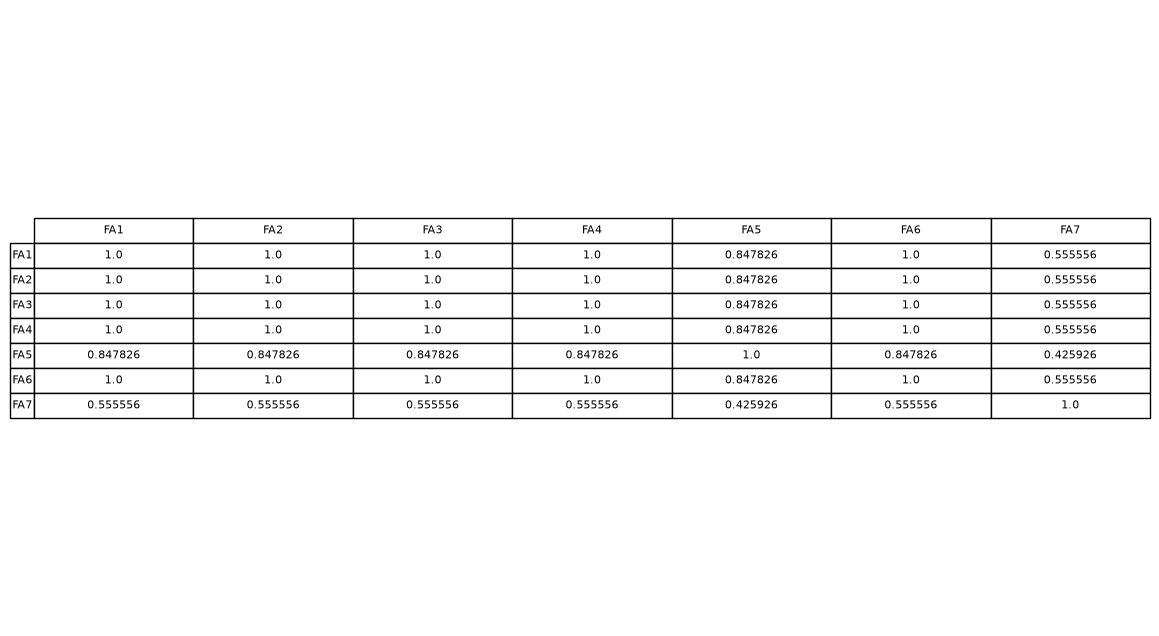

In [45]:
#Making the Tanimoto matrix
# Convert SMILES strings to RDKit molecules
molecules = np.array([Chem.MolFromSmiles(smile) for smile in smiles_list_fig3])

# Find the molecule with the largest number of atoms
num_qubits = max(mol.GetNumAtoms() for mol in molecules if mol is not None)

max_atoms = max(mol.GetNumAtoms() for mol in molecules if mol is not None)


# Generate fingerprints for each molecule
fpgen = rdFingerprintGenerator.GetRDKitFPGenerator(fpSize=2048)
# fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=4, includeChirality=True, fpSize=2048)
fingerprints = ([fpgen.GetFingerprint(mol) for mol in molecules])


print(f"Maximum atoms: {max_atoms}")
print(f"Atoms per qubit: {n_atom_to_qubit}")
print(f"Number of qubits: {num_qubits}")

# Calculate Tanimoto similarity matrix
n = len(fingerprints)
tanimoto_matrix = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if i != j:
            tanimoto_matrix[i][j] = DataStructs.FingerprintSimilarity(fingerprints[i], fingerprints[j])
        else:
            tanimoto_matrix[i][j] = 1.0  # Similarity with itself is 1

# Display the Tanimoto similarity matrix
tanimoto_df = pd.DataFrame(tanimoto_matrix, index=smiles_list_fig3, columns=smiles_list_fig3)
tanimoto_df_rounded = tanimoto_df.round(6)

#print Tanimoto matrix for figure 3
fig, ax = subplots(figsize=(12, 8))
ax.axis('off')
table = ax.table(cellText = tanimoto_df_rounded.values, rowLabels = fatty_acid_labels ,colLabels = fatty_acid_labels, loc = 'center', cellLoc = 'center')

table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1.2, 1.5)

#plt.tight_layout()
#plt.savefig('tanimoto_table_4.pdf', bbox_inches='tight', dpi=300)


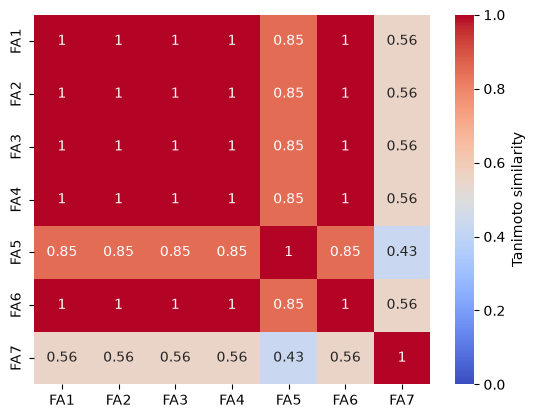

In [46]:
# importing the modules
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
  
# plotting the heatmap
hm = sns.heatmap(data=tanimoto_df_rounded,
                annot=True, xticklabels=fatty_acid_labels, yticklabels=fatty_acid_labels,
    cmap="coolwarm",  vmin=0,
    vmax=1,
    cbar_kws={"label": "Tanimoto similarity"}
)

# displaying the plotted heatmap
plt.show()

In [47]:
from quantum_molecular_encodings.supporting_functions import quantum_overlap

overlap_df_x_xx = quantum_overlap(num_qubits, smiles_list_fig3, entangling_layer = 'rxx', n_atom_to_qubit=1, interleaved='ryy', n_layers=1)
#overlap_df_x_yy = quantum_overlap(num_qubits, smiles_list, entangling_layer = 'ryy', n_atom_to_qubit=1, interleaved='ryy', n_layers=1)
#TODO: test with different n_atom_to_qubit values
#overlap_df_x_zz = quantum_overlap(num_qubits, smiles_list, entangling_layer = 'rzz', n_atom_to_qubit=1, interleaved='ryy', n_layers=1)
overlap_df = pd.DataFrame(overlap_df_x_zz, index=smiles_list, columns=smiles_list)

MemoryError: Unable to allocate 7.00 TiB for an array with shape (7, 68719476736) and data type complex128